# Noisy modulated signal → UART bytes

### 45-minute medium challenge | Python standard library only

**Your task:** recover an unknown ASCII message from a noisy, sampled digital signal. The sender uses a carrier to represent logic levels, then UART-style **8N1** framing to send bytes. You must decide how to reduce noise, determine each bit, and reconstruct the bytes.

This is an original practice scenario for signal-processing and Python fundamentals. It focuses on arithmetic, loops, lists, indexing, slicing, and a working implementation without third-party libraries.

**What you are given**
- Sample rate: **8,000 samples/second**; bit rate: **400 bits/second**.
- You are told the sample stream starts exactly on a bit boundary and timing does not drift. You do **not** need clock recovery.
- Line idle = **1**, start bit = **0**, **8 data bits sent LSB-first**, stop bit = **1**; there are idle bits between frames.
- Signal readings are *signed* (can be positive or negative), with random noise, occasional spikes, and a small DC bias.
- Carrier present means bit **1**; carrier absent means bit **0**. A carrier alternates above and below zero, so averaging the **raw signed voltage** can hide the carrier.

**Deliverables:** `symbol_strength(window)`, `recover_bits(samples, samples_per_bit, threshold)`, and `decode_uart(bits)`. A local judge checks each function and the recovered message without printing the answer.

**Suggested clock:** inspect 0–7 min · filter/detector 7–20 min · bits 20–28 min · UART bytes 28–40 min · validation 40–45 min.

The next cell **contains the received data**. Run it. You can ignore its long list of numbers.

In [7]:
samples = [
    0.6828, 1.4142, 0.5349, -0.8434, -0.3409, 0.6792, 1.0037, -0.0436, -0.6441, -0.6643, 0.5205, 1.3166,
    0.3635, -0.3921, -0.3677, 0.6427, 1.0042, 0.1785, -0.7217, -0.3305, 0.1969, 0.8629, 0.2812, -0.9077,
    -0.7565, 0.6309, 1.2485, 0.4326, -0.8499, -0.8727, 0.3676, 0.9702, 0.0733, -0.6134, -0.7331, 0.5508,
    0.9225, 0.5258, -0.8050, -0.5817, 0.5548, 0.6255, 0.3535, -3.0557, -0.7325, 0.6859, 1.0718, 0.0544,
    -0.6218, -0.5568, 0.2710, 1.0873, 0.4398, -0.6514, -0.4942, 0.3113, 1.0472, 0.5239, -0.8653, -0.6625,
    0.3578, 0.1584, 0.3019, 0.0431, 0.1898, 0.0868, 0.0670, 0.0677, -0.0668, 0.0147, 0.0319, -0.0148,
    -0.1116, 0.1393, -0.1457, 0.0354, 0.3485, 0.1418, 0.2731, 0.0483, 0.2148, -0.0041, 0.1050, 0.2549,
    0.0822, -0.2560, 0.1932, 0.4183, 2.7652, -3.2996, 3.1641, 0.2499, 0.0088, 0.2258, 0.4645, -0.2038,
    0.2312, 0.0320, 0.1700, -0.1468, 0.1659, 0.1191, -0.0301, -0.1535, 0.2228, 0.3122, 0.2828, 0.2937,
    0.1862, -0.0717, -0.1678, 0.2739, 0.1379, -0.1365, 0.2511, -0.0480, -0.1356, 0.0359, 0.0832, 0.3570,
    0.4812, 1.5078, 0.2989, -0.7316, -0.3240, 0.4546, 1.1743, 0.6351, -0.4708, -0.9363, 0.4105, 1.1180,
    0.3788, -0.7933, -0.5765, 0.6205, 1.0975, 0.3288, -0.7039, -0.3526, 0.1770, 0.0834, 0.0970, 0.2064,
    0.1711, 0.1707, 0.0643, 0.3324, 0.1038, 0.3237, 0.2937, 0.0970, -0.0012, -0.0259, 0.1516, 0.4187,
    -0.1819, 0.1165, 0.3891, 0.0461, 0.3230, 0.3915, 0.2615, 0.3745, 0.0840, 0.2428, -0.0698, 0.0976,
    3.1668, -2.9837, 2.7357, 0.0723, -0.0860, -0.0409, 0.3206, 0.0677, 0.1449, -0.0305, 0.2274, 0.3863,
    0.1587, 0.1750, -0.1358, -2.1377, 0.2292, 0.0599, 0.5367, 0.1810, -0.3488, 0.1265, -0.0004, 0.2725,
    -0.0119, -0.2044, 0.3225, 0.3620, 0.3926, -0.1174, 0.1493, 0.1218, 0.3012, 1.0062, 0.6204, -0.7209,
    -0.6806, 0.4865, 1.1022, 0.4897, -0.9924, -0.4570, 0.4637, 1.0239, 0.4357, -0.7761, -0.4153, 0.3828,
    0.9144, 0.4066, -0.6540, -0.7321, 0.3785, 0.3991, 0.0374, 0.1263, 0.1586, -0.0847, 0.4096, 0.1855,
    0.1930, 0.0273, 0.3340, -0.2502, 0.5264, 0.1059, 0.3391, 0.1146, 0.2697, 0.0335, -0.0510, 0.2150,
    0.8085, 1.0613, 0.1813, -0.6824, -0.6540, 0.7510, 1.3734, 0.2048, -0.8695, -0.3581, 0.5424, 0.9448,
    0.4033, -0.8045, -0.9881, 0.1853, 1.0831, 0.3902, -0.9432, -0.4611, 0.7337, 1.2512, 0.4699, -0.8947,
    -0.5015, 0.3764, 1.1524, 0.4697, -1.0591, -0.6480, 0.8244, 1.0292, 0.4117, -0.7202, -0.4462, 0.4319,
    1.0348, 0.5218, -0.9641, -0.4493, 0.3095, 1.2982, 0.3816, -0.4910, -0.6684, 0.4233, 1.2039, 0.3750,
    -0.7771, -0.8128, 0.1801, 1.4143, 0.3895, -0.5597, -0.7975, 0.2536, 1.0397, 0.4278, -0.8908, -0.5725,
    0.2064, -0.1610, 0.0621, 0.2136, 0.2811, 0.1423, 0.1022, 0.1839, 2.9341, -2.9030, 3.0419, -0.1078,
    -0.0558, -0.1665, 0.3814, 0.2009, 0.1520, 0.2624, 0.1452, 0.1648, 0.4326, 1.5169, 0.2059, -0.7518,
    -0.6437, 0.6432, 0.9220, 0.3650, -0.5050, -0.6850, 0.5014, 1.2954, 0.4278, -0.7698, -0.8849, 0.3117,
    1.2095, 0.2707, -0.5117, -1.0295, -0.0278, 0.1813, 0.3391, 0.1736, 0.1830, 0.2771, 0.0079, 0.1721,
    0.0821, -0.0506, 0.0680, -0.0187, 0.0848, -0.1770, 0.0261, -0.1607, 0.1457, -0.0336, 0.0277, -0.0001,
    0.0297, 0.2620, -0.2799, -2.9026, -0.0229, 0.0135, 0.1306, 0.4125, -0.2064, 0.1958, 0.0201, -0.1349,
    -0.0985, 0.2993, 0.1911, 0.3322, 0.1811, 0.1110, 0.0680, -0.0741, -0.0293, 0.2193, 0.1852, 0.0945,
    -0.0820, 0.1391, -0.0267, -0.1138, -0.1151, -0.3620, 0.2479, -0.1882, -0.0090, 0.0608, -0.0174, -0.1508,
    -0.0123, 0.1505, -0.0239, -0.2377, -0.2236, 0.2748, 0.2382, 0.2837, -0.0708, 0.0937, -0.0145, -0.1701,
    0.3000, -0.0155, 0.0757, 0.0489, 0.0396, -0.0689, 0.2476, -0.1064, -0.1260, -0.0601, -0.0526, 0.0347,
    -0.0836, -0.1331, -0.2616, -0.0020, -0.0490, -0.2613, 0.1987, -0.0854, 0.0826, 0.0127, 0.0758, 0.0456,
    -0.2608, 0.1407, -0.3869, 0.1557, -0.0908, -0.1680, -0.2156, 0.0085, 0.2200, 0.8587, 0.1974, -0.7340,
    -1.0130, 0.4650, 0.9009, 0.1839, -0.7680, -0.7374, 0.3219, 1.0630, 0.2198, -1.0042, -0.7875, 0.4857,
    0.9505, 0.6198, -0.9532, -0.8917, 0.0105, 0.0084, -0.0409, 0.0978, -0.0893, 0.0766, 0.2737, -0.2052,
    -0.0947, 0.0285, -0.0818, 0.1408, 0.0841, 0.0203, -0.1406, -0.0686, -0.0028, 0.0840, 0.1257, -0.0119,
    0.1620, 0.6608, 0.1370, -0.8271, -0.7091, 0.3854, 1.1240, 0.7794, -1.0396, -0.6292, 0.4514, 0.9880,
    -0.0767, -0.5525, -0.7209, 0.4891, 0.8487, 0.2235, -1.1534, -0.8664, 0.1653, 1.0205, 0.3202, -0.7444,
    -1.0474, 0.7442, 1.0526, 0.0220, -0.6733, -0.5809, 0.5707, 0.8570, 0.4781, -0.6402, -0.6051, 0.2926,
    1.0103, 0.1104, -0.7241, -0.6019, 0.2755, 0.7609, 0.1895, -0.8749, -0.4948, 0.3627, 0.7787, 0.2722,
    -0.6417, -0.6024, 0.6607, 1.1492, 0.4751, -0.6007, -0.8483, 0.2260, 0.8279, 0.3825, -0.8993, -0.6838,
    -0.1502, -0.0371, 0.0950, -0.0712, 0.1173, 0.0060, -0.4711, 0.0068, 0.0747, -0.3477, -0.2127, 0.2072,
    -0.0217, 0.1163, -0.0741, 0.2796, 0.0465, -0.1572, 0.2700, 0.2410, -0.2246, 0.1244, -0.0769, -2.5826,
    0.2277, -0.0757, 0.2076, 0.0973, 0.2018, 0.0565, 0.0608, 0.0867, -0.1511, 0.2415, 0.2104, -0.2030,
    0.0162, -0.1865, -0.2221, -0.1948, 0.0816, -0.0618, 0.0264, 0.1622, 0.0726, 0.3199, 0.0584, 0.0146,
    0.3175, -0.0390, -0.0765, -0.1019, -0.3121, -0.0825, -0.1203, -0.1715, 0.2258, -0.1744, 0.0361, -0.0558,
    0.3302, 1.0572, 0.5480, -0.9255, -0.8904, 0.4735, 1.0236, 0.2354, -0.7025, -0.6247, 0.1886, 1.0110,
    0.4407, -0.9632, -0.8997, 0.3815, 1.0139, 0.3077, -0.5412, -0.9828, 0.2209, -0.0723, -0.2149, -0.0313,
    -0.0852, -0.1592, 0.0810, -0.1675, 0.1172, -0.0229, 0.2110, -0.1323, -0.2134, 0.3562, -0.1335, -0.1002,
    -0.1795, 0.0524, 0.3612, 0.2111, 0.0297, 0.9865, 0.2496, -0.5518, -0.3403, 0.1748, 0.7803, 0.1529,
    -1.0366, -0.7937, 0.3585, 0.7729, 0.3169, -0.5971, -0.5877, 0.2692, 1.0930, 0.1754, -0.7636, -0.3975,
    0.1872, -0.1285, -0.0059, 0.1328, 0.0023, -0.0681, 0.0382, 0.0921, 0.1228, 0.0278, 0.0813, 0.1509,
    -0.2001, 0.1120, -0.2917, 0.2829, -0.0551, -0.2076, 0.0415, -0.1345, 0.1083, 0.8436, 0.2861, -1.0797,
    -0.5751, 0.1547, 0.8496, 0.1039, -0.7896, -0.7779, 0.3470, 0.8841, 0.1308, -0.6932, -0.8304, 0.3135,
    0.6947, 0.0792, -0.8203, -0.5473, 0.0032, -0.0739, 0.1338, 0.2032, 0.1039, 0.2132, -0.0684, -0.0590,
    0.1235, -0.0371, 0.3824, -0.1536, 0.0348, 0.0059, -0.0025, -0.0601, 0.0873, 0.1668, 0.2970, -0.2874,
    0.2715, 1.0215, 0.2415, -0.6346, -0.5708, 0.3812, 0.9565, 0.0645, -0.5230, -0.6244, 0.4462, 0.7453,
    0.1655, -0.8291, -0.3739, 0.3810, 0.8201, 0.3299, -0.8150, -0.5789, 0.7195, 0.6960, 0.3820, -0.6361,
    -0.8348, 0.7045, 1.0821, 0.2960, -0.6560, -0.2294, 0.3597, 0.8959, 0.0234, -0.8541, -0.4267, 0.3661,
    1.0698, 0.3079, -0.8182, -0.5274, 0.4097, 0.9498, 0.2958, -0.5378, -0.5322, 0.1347, 0.8610, 0.2238,
    -0.9812, -0.2942, 0.4135, 1.0067, 0.2784, -0.5093, -0.4891, 0.2987, 0.8507, 0.2372, -0.6787, -0.4942,
    -0.0469, 0.1268, 0.3339, 0.1213, 0.0675, 0.1532, 0.0028, -0.0309, -0.1794, -0.0412, 0.2529, -0.0623,
    0.0609, -0.0043, 0.6599, -0.1494, 0.2381, 0.1754, 0.3216, 0.1052, 0.4127, 0.6481, 0.5581, -0.4445,
    -0.6405, 0.5835, 1.2313, 0.3313, -0.7495, -0.6193, 0.8853, 0.8846, 0.4300, -0.4782, -0.5794, 0.5570,
    0.9570, 0.3202, -0.5524, -0.6781, -0.1396, 0.0184, -0.0044, 0.1175, 0.3594, 0.0445, 0.3459, -0.0101,
    0.0894, 0.2405, 0.1968, 0.1618, 0.1618, -0.1481, 0.1662, 0.2997, 0.1603, 0.1464, 0.3857, 0.1980,
    0.0740, 0.0247, -0.2025, 0.2200, 0.1065, 0.6240, 0.1293, 0.0882, 0.0505, 0.2340, 0.3268, 0.3246,
    -0.1420, 0.1958, 0.1887, -0.0503, 0.2035, 0.2222, -0.1236, 0.0735, 0.0383, 0.0713, 0.2569, 0.0234,
    -0.0697, 0.1218, 0.1591, -0.0497, 0.0374, 0.0469, 0.2064, 0.1282, 0.0255, -0.0322, 0.3657, -0.2635,
    0.5240, 0.4333, 0.2621, -0.1201, 0.2220, 0.2442, 0.1651, 0.0338, -0.0358, 0.1465, 0.4189, 0.2755,
    2.6481, -3.0951, 2.9306, 0.2065, 0.1569, 0.4627, 0.1793, 0.2209, 0.3450, 0.0666, -0.1640, 0.0214,
    0.2679, 0.2580, 0.3544, -2.5041, 0.2511, 0.2034, -0.0160, 0.1277, 0.1438, 0.1129, 0.1214, 0.3922,
    0.3100, 0.1147, 0.0772, 0.2520, 0.2853, 0.2848, -0.0882, -0.0037, 0.5428, 1.0644, 0.0443, -0.6227,
    -0.6055, 0.2264, 1.1190, 0.7046, -0.7906, -0.6170, 0.5590, 0.8816, 0.4665, -0.6938, -0.4261, 0.4691,
    0.9627, 0.2703, -0.4627, -0.7112, 0.5504, 0.0539, 0.0846, 0.1000, 0.1498, 0.1416, 0.1101, 0.3653,
    0.3984, 0.0007, 0.0735, -0.2613, 0.1647, 0.3126, 0.1682, 0.2308, 0.2725, 0.3137, 0.3352, 0.4097,
    0.1925, 0.9754, 0.4528, -0.6529, -0.6162, 0.4133, 0.9558, 0.4605, -0.1918, -0.4133, 0.5765, 0.8195,
    0.2306, -0.6598, -0.3183, 0.6550, 1.1506, 0.1439, -0.6497, -0.3447, 0.4810, 1.1390, 0.4619, -0.5673,
    -0.3689, 0.4529, 1.2311, 0.3531, -0.8014, -0.6616, 0.1297, 1.0507, 0.4342, -0.9984, -0.4660, 0.8334,
    0.7891, 0.3321, -0.8208, -0.5807, 0.9199, 0.9890, 0.3527, -0.3698, -0.3713, 0.4654, 0.7690, 0.3230,
    -0.6792, -0.7581, 0.0800, 1.2641, 0.1487, -0.6514, -0.8683, 0.4279, 1.1919, 0.5943, -0.5138, -0.7006,
    0.2851, 0.9879, 0.2520, -0.6533, -0.8821, 0.5186, 1.0086, 0.4710, -0.5724, -0.4821, 0.6816, 1.0676,
    -0.0097, -0.8028, -0.2870, 0.7231, 1.0755, 0.5665, -0.6339, -0.5137, 0.4878, 0.9132, 0.3380, -0.5324,
    -0.6317, 0.6057, 1.0837, 0.1996, -0.6212, -0.1678, 0.4498, 0.7162, 0.2071, -0.8691, -0.4975, 0.4384,
    0.9522, 0.3984, -0.7005, -0.4700, 0.3380, 1.1563, 0.3181, -0.5748, -0.6767, 0.3136, 1.4742, 0.4079,
    -0.7569, -0.8107, 0.4884, 0.8798, 0.2910, -0.7849, -0.3968, 0.6274, 1.1713, 0.2653, -0.8849, -0.6037,
]

SAMPLE_RATE = 8000     # measured samples per second
BAUD_RATE = 400        # UART-style bit rate
SAMPLES_PER_BIT = SAMPLE_RATE // BAUD_RATE

print(f"Loaded {len(samples)} samples ({len(samples) / SAMPLE_RATE:.3f} seconds)")
print(f"Samples per bit: {SAMPLES_PER_BIT}")

Loaded 1080 samples (0.135 seconds)
Samples per bit: 20


## 1. Inspect the capture (5–7 minutes)

First look at the data. Do the samples resemble a two-level voltage, or an oscillating carrier? How should you measure the signal if positive and negative swings cancel?

**C++ → Python reminders:**

| C / C++ | Python |
|---|---|
| `std::vector<double> xs` | `xs = []` |
| `xs.push_back(v)` | `xs.append(v)` |
| `for (int i=0; i<n; ++i)` | `for i in range(n):` |
| `xs[i]` | `xs[i]` |
| iterate `xs[start]` to `xs[end-1]` | `xs[start:end]` |
| `std::abs(x)` | `abs(x)` |
| `std::sort(v.begin(),v.end())` | `sorted(v)` |
| integer `a / b` when both int (C++) | `a // b` for floor division (Python) |

The *end of a slice is excluded*: `samples[20:40]` has 20 values, indices 20 through 39.

In [8]:
# Exploration, not part of the graded solution.
print("First 16 voltage samples:", samples[:16])
print("Lowest / highest recorded values:", min(samples), max(samples))
print("First six bit windows: raw mean versus average absolute voltage")

for start in range(0, 6 * SAMPLES_PER_BIT, SAMPLES_PER_BIT):
    window = samples[start:start + SAMPLES_PER_BIT]
    signed_mean = sum(window) / len(window)
    magnitude_mean = sum(abs(x) for x in window) / len(window)
    print(f"bit-window {start // SAMPLES_PER_BIT:>2}: signed={signed_mean:+.3f}   abs={magnitude_mean:.3f}")

First 16 voltage samples: [0.6828, 1.4142, 0.5349, -0.8434, -0.3409, 0.6792, 1.0037, -0.0436, -0.6441, -0.6643, 0.5205, 1.3166, 0.3635, -0.3921, -0.3677, 0.6427]
Lowest / highest recorded values: -3.2996 3.1668
First six bit windows: raw mean versus average absolute voltage
bit-window  0: signed=+0.200   abs=0.634
bit-window  1: signed=+0.047   abs=0.659
bit-window  2: signed=-0.031   abs=0.733
bit-window  3: signed=+0.098   abs=0.132
bit-window  4: signed=+0.233   abs=0.625
bit-window  5: signed=+0.099   abs=0.173


### Optional plot (not required for the interview)

Matplotlib is **optional**. This cell simply gives you a picture of the first 10 bit intervals if you have it installed. No plots or third-party imports are needed to solve the exercise.

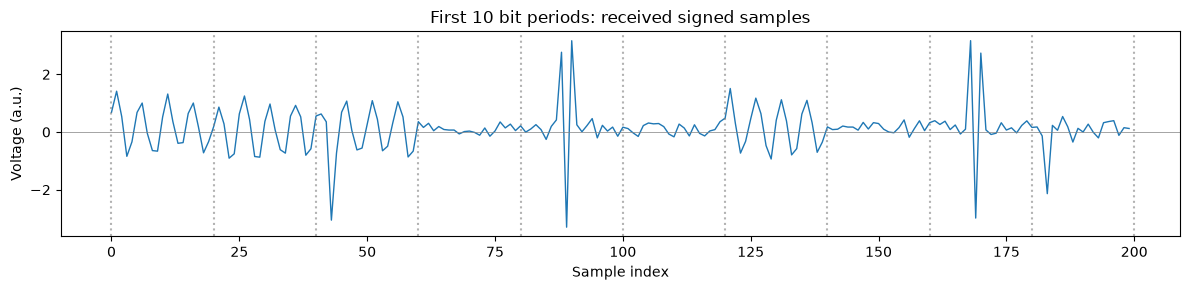

In [9]:
try:
    import matplotlib.pyplot as plt
    n = 10 * SAMPLES_PER_BIT
    plt.figure(figsize=(12, 3))
    plt.plot(range(n), samples[:n], linewidth=1)
    for edge in range(0, n + 1, SAMPLES_PER_BIT):
        plt.axvline(edge, color="gray", linestyle=":", alpha=0.6)
    plt.axhline(0, color="gray", linewidth=0.5)
    plt.title("First 10 bit periods: received signed samples")
    plt.xlabel("Sample index")
    plt.ylabel("Voltage (a.u.)")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Optional matplotlib not installed. Use the printed statistics above instead.")

## 2. Choose a noise-resistant filter / detector (10–13 minutes)

A naive low-pass filter of the **raw signed signal** may average a carrier to almost zero. You need a measurement that reflects whether the carrier is present.

You may use an envelope-style measure such as `abs(x)` followed by smoothing, or take a median of the absolute values in each window. **Isolated spikes** are a reason to compare mean and median.

Implement `symbol_strength(window)` so it returns a **larger number when a carrier is present** and stays small on a mostly quiet window, even with a single impulse spike. You may use built-ins like `abs`, `sum`, `len`, and `sorted`.

Useful syntax: `ordered = sorted(values)`; for an odd-length list, its median is `ordered[len(ordered) // 2]`. With even-length lists, you can use one of the two center values or their average.

**What your function should do**
- `[0.0] * 19 + [4.0]` represents mostly quiet samples with one large spike. Its strength should remain low.
- A sequence that alternates positive and negative values, e.g. `[1, -1] * 10`, represents a strong carrier, even though its signed mean is zero.
- It should work on windows with 20 samples, but don't hardcode the length.

In [19]:
def symbol_strength(window):
    # TODO: measure carrier strength despite positive/negative oscillation.
    # TODO: resist isolated large spikes.
    ordered = []
    for x in window:
        ordered.append(abs(x))
    ordered = sorted (ordered)
    median = ordered[len(ordered)//2]
    return median

    # Return one number.
    pass

In [20]:
# Test your detector, without showing you the real transmitted message.
def check_detector():
    try:
        quiet = symbol_strength([0.0] * 20)
        carrier = symbol_strength([1.0, -1.0] * 10)
        impulsive = symbol_strength([0.0] * 19 + [4.0])
        if any(x is None for x in (quiet, carrier, impulsive)):
            print("Not implemented yet: replace 'pass' in symbol_strength")
            return
        assert quiet < 0.2, f"Quiet window should be low; got {quiet:.3f}"
        assert carrier > 0.6, f"Strong carrier should be high; got {carrier:.3f}"
        assert impulsive < 0.3, f"One spike should not look like a carrier; got {impulsive:.3f}"
        print("PASS: detector distinguishes carrier from quiet samples and rejects a single spike")
    except (AssertionError, TypeError, ZeroDivisionError, ValueError) as exc:
        print("CHECK FAILED:", exc)
check_detector()

PASS: detector distinguishes carrier from quiet samples and rejects a single spike


## 3. Convert the samples into bits (8 minutes)

You have `SAMPLES_PER_BIT = 20`. For each 20-sample window, compute the detector output and classify it as `0` or `1` using a threshold. Start with **`threshold = 0.36`** (in the units returned by a *median-absolute-amplitude* detector). If you use a different measurement, choose a threshold that separates its low and high values.

Implement `recover_bits(samples, samples_per_bit, threshold)` returning a list of Python integers (`0` and `1`). It should work for any capture whose length is a multiple of samples_per_bit.

Syntax reminder: `range(0, len(samples), samples_per_bit)` behaves like `for (int i=0; i<n; i+=step)`.

**Expected shape:** one bit per window; the result should contain **54 bits**. The initial idle line should give several 1s.

In [21]:
def recover_bits(samples, samples_per_bit, threshold):
    bits = []
    for i in range (0,len(samples)-samples_per_bit + 1,samples_per_bit):
        window = samples[i:i+samples_per_bit]
        #threshold check abs and median
        filtered = symbol_strength (window)
        if (filtered >= threshold):
            bits.append(1)
        else:
            bits.append(0)
    return bits
    # TODO: walk through the sample stream in fixed-size windows.
    # TODO: call symbol_strength(window), compare with threshold.
    # TODO: append each decoded bit to 'bits'.

    return bits

In [22]:
threshold = 0.36  # sensible for median(abs(window)); adjust for your detector
bits = recover_bits(samples, SAMPLES_PER_BIT, threshold)

print("Number of recovered bits:", len(bits))
print("First 18 recovered bits:", bits[:18])
print("Bit recovery:", "PASS" if len(bits) == 54 and bits[:3] == [1, 1, 1] else "NOT YET")

Number of recovered bits: 54
First 18 recovered bits: [1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0]
Bit recovery: PASS


## 4. Decode UART-like 8N1 frames (12 minutes)

Now you have a normal list of 0 and 1 bits. The framing is UART-style:

`idle=1  |  start=0  |  d0 d1 d2 d3 d4 d5 d6 d7  |  stop=1  |  idle=1 ...`

- Detect a candidate start bit at a **1 → 0** transition.
- The following **8 bits** are data, least-significant bit first.
- The next bit must be **1** (stop bit). Reject invalid frames.
- Move past a decoded frame so falling edges **inside its data** aren't mistaken for new frames.
- Return a list of byte values (integers from 0 through 255).

**C++:** `value |= bit << k;` translates directly to Python: `value |= bit << k`.

Don't hardcode the answer; reconstruct it from your recovered bits.

In [34]:
def decode_uart(bits):
    decoded = []
    i =1

    while i + 9 <len(bits):
        #falling edge
        edge = (bits[i-1] == 1 and bits[i]==0)
        stop_bit = (bits[i+9] == 1)

        if (edge and stop_bit):
            value =0
            for k, bit in enumerate(bits[i+1:i+9]):
                value |= (bit << k)
            decoded.append (value)
            i+=10
        else:
            i+=1

    return decoded
        
      

            



    # TODO: loop while there is space for a complete 10-bit frame.
    # TODO: find a falling edge (previous bit=1 and current bit=0).
    # TODO: validate stop bit at i+9.
    # TODO: reconstruct data from bits[i+1:i+9], LSB first.
    # TODO: append the byte value; jump past the frame.

    return decoded

In [35]:
# Small independent test: a frame for ASCII 0x41 (capital A).
known_bits = [1, 0, 1,0,0,0,0,0,1,0, 1, 1]
result = decode_uart(known_bits)
print("8N1 sanity check:", "PASS" if result == [65] else f"NOT YET: {result}")

8N1 sanity check: PASS


## 5. Final local judge (5 minutes)

Run this after filling in the three functions. It validates the bitstream and uses a **checksum** to check the recovered ASCII payload without revealing the expected message.

A checksum is just for **grading this exercise**. The actual transmission described here does not include a checksum field.

In [36]:
import hashlib

def grade_submission():
    try:
        got_bits = recover_bits(samples, SAMPLES_PER_BIT, threshold)
        if len(got_bits) != 54:
            print(f"Bit count incorrect: expected 54, got {len(got_bits)}")
            return
        if any(bit not in (0, 1) for bit in got_bits):
            print("Bitstream contains values besides 0 and 1")
            return

        recovered = decode_uart(got_bits)
        if len(recovered) != 4:
            print(f"Frame count incorrect: expected 4 ASCII bytes, got {len(recovered)}")
            return
        try:
            message = bytes(recovered)
        except ValueError as exc:
            print("Invalid byte value:", exc)
            return
        expected_digest = "c97c29c7a71b392b437ee03fd17f09bb10b75e879466fc0eb757b2c4a78ac938"
        if hashlib.sha256(message).hexdigest() == expected_digest:
            print("PASS! You recovered the transmitted ASCII message correctly.")
            print("Decoded message:", message.decode("ascii"))
        else:
            print("Not quite. Correct number of frames, but the decoded bytes don't match the capture.")
            print("Your bytes:", recovered)
            print("Check thresholding, framing, bit order, and frame spacing.")
    except Exception as exc:
        print("Your implementation raised an exception:", type(exc).__name__, str(exc))

grade_submission()

PASS! You recovered the transmitted ASCII message correctly.
Decoded message: DATA


## If you get stuck: progressive hints (open only as needed)

<details><summary><strong>Hint 1: Why the raw mean is misleading</strong></summary>

The high bit consists of a carrier with positive and negative swings. The signed average can be small for both 0 and 1. Transform the samples to nonnegative magnitudes first (`abs(x)` or `x*x`) before combining them.
</details>

<details><summary><strong>Hint 2: Which filtering approach works well with spikes?</strong></summary>

A regular average responds strongly to a few large outliers. Try taking `sorted(abs(x) for x in window)` and looking near the middle of the sorted list. This estimates typical carrier magnitude instead of total energy.
</details>

<details><summary><strong>Hint 3: How should the bit loop advance?</strong></summary>

Use `for start in range(0, len(samples), samples_per_bit):` and get each interval using `window = samples[start:start+samples_per_bit]`. Then append `1` or `0` depending on the detector score.
</details>

<details><summary><strong>Hint 4: How should UART parsing advance?</strong></summary>

If position `i` is a start bit, the data bits are `bits[i+1]` through `bits[i+8]`, the stop bit is `bits[i+9]`, and you should advance at least 10 bit positions after decoding the frame. Otherwise advance one position to keep scanning.
</details>

## Optional bonus: compare filter behaviors

This is outside the core 45-minute task. Write a *causal* moving-average low-pass filter on the **absolute values**. This is called rectification followed by smoothing.

For each sample index `i`, take the previous `width` magnitudes (or fewer near the beginning), average them, and append the result. Compare widths 3, 7, and 15. What happens around bit transitions? Would a single large impulse affect the moving average more than your median-based detector?

The important tradeoff: wider smoothing reduces random noise but can smear rapid bit changes.

In [ ]:
def rectified_moving_average(samples, width):
    out = []
    # TODO (bonus): return a list of the same length as samples,
    # with a causal moving average of abs(samples).
    return out

# Example optional test after implementing:
# assert rectified_moving_average([-1, 0, 1], 2) == [1.0, 0.5, 0.5]

## Bonus: read a real CSV capture

The downloadable package also contains `captured_signal.csv`. Put it in the same folder as this notebook, then run this cell. The file has a header plus two columns: sample index and voltage. Reading this is useful practice for receiving an unfamiliar file in Jupyter.

The embedded `samples` data above means the notebook **still runs without the CSV file**.

In [ ]:
# Optional: standard-library CSV import, no pandas/numpy required.
try:
    import csv
    file_samples = []
    with open("captured_signal.csv", newline="") as file:
        rows = csv.DictReader(file)
        for row in rows:
            file_samples.append(float(row["voltage"]))
    print("CSV loaded:", len(file_samples), "samples")
    print("Matches embedded capture:", file_samples == samples)
except FileNotFoundError:
    print("CSV not found. That's okay: the embedded sample data is already loaded.")